In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
data = pd.read_csv("C:/Users/hp/Desktop/undertrials_time series/undertrials.csv")
data['Year'] = pd.to_datetime(data['Year'], format='%Y') + pd.offsets.YearEnd(0)
data.set_index('Year', inplace=True)
print(data)

            Undertrials
Year                   
2023-12-31       389910
2022-12-31       434302
2021-12-31       427165
2020-12-31       371848
2019-12-31       330487
2018-12-31       323537
2017-12-31       308718
2016-12-31       293058
2015-12-31       282076
2014-12-31       282879
2013-12-31       278503
2012-12-31       254857
2011-12-31       241200
2010-12-31       240098
2009-12-31       250204
2008-12-31       257928
2007-12-31       250727
2006-12-31       245244
2005-12-31       237076
2004-12-31       217130
2003-12-31       217658
2002-12-31       223038
2001-12-31       220817
2000-12-31       193627
1999-12-31       204480
1998-12-31       202564
1997-12-31       184247
1996-12-31       208269
1995-12-31       199359


In [28]:
data = data.asfreq('YE')

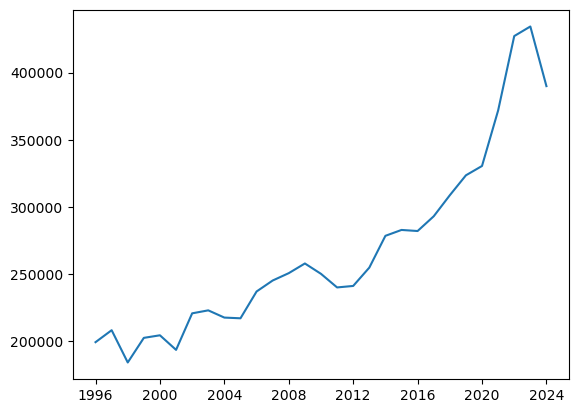

In [29]:
plt.plot(data)
plt.show()

In [30]:
# checking if data is stationary or not
from statsmodels.tsa.stattools import adfuller
adftest = adfuller(data['Undertrials'])
def adf_test():
    pvalue = adftest[1]
    print('pvalue of adfuller test is:', pvalue)
    if pvalue <= 0.05:
        print("Stationary dataset")
    else:
        print("Non-stationary dataset")
adf_test()

pvalue of adfuller test is: 0.9932192502658994
Non-stationary dataset


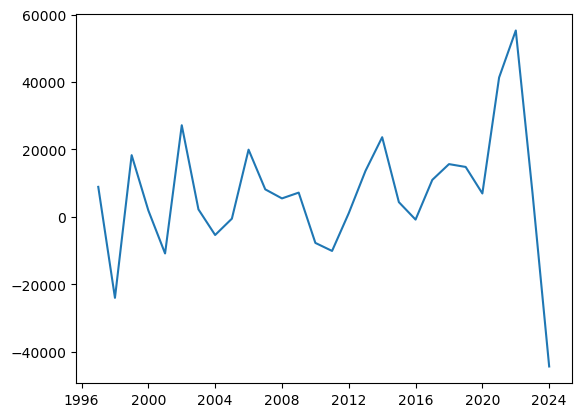

In [31]:
# implementing differencing
data['Undertrials_diff'] = data['Undertrials'].diff()

plt.plot(data['Undertrials_diff'])
plt.show()

In [32]:
adftest = adfuller(data['Undertrials_diff'].dropna())
adf_test()

pvalue of adfuller test is: 0.0001948087199205976
Stationary dataset


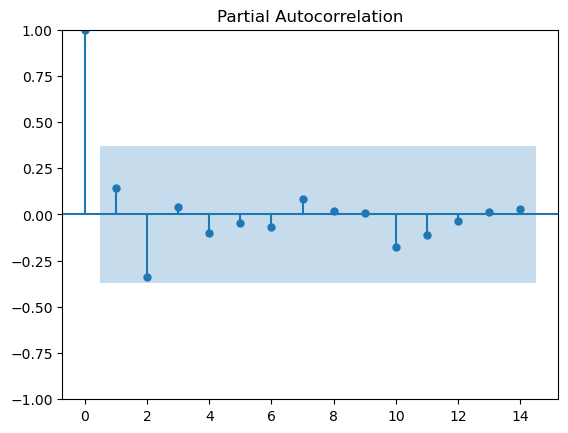

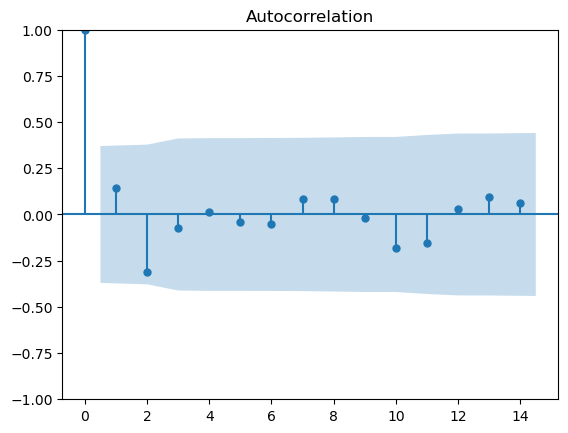

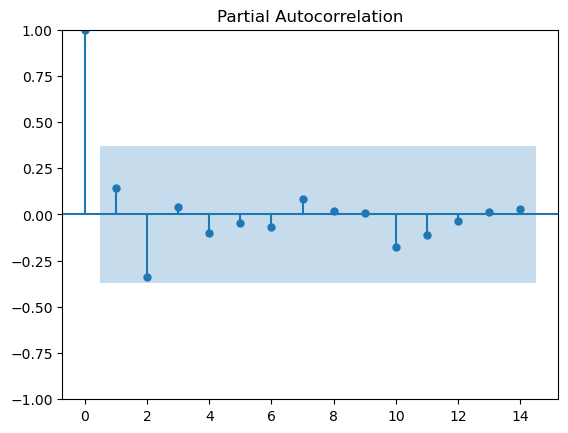

In [33]:
# implementing ARIMA model
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(data['Undertrials_diff'].dropna())
plot_pacf(data['Undertrials_diff'].dropna())

In [34]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(data['Undertrials'], order=(1,1,1),trend='t')
result = model.fit()
print(result.summary())

                               SARIMAX Results                                
Dep. Variable:            Undertrials   No. Observations:                   29
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -313.205
Date:                Wed, 31 Dec 2025   AIC                            634.410
Time:                        20:54:42   BIC                            639.739
Sample:                    12-31-1995   HQIC                           636.039
                         - 12-31-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1          6805.3928   3678.426      1.850      0.064    -404.189     1.4e+04
ar.L1         -0.4922      0.495     -0.995      0.320      -1.462       0.477
ma.L1          0.6440      0.494      1.302      0.1

In [35]:
from statsmodels.tsa.arima.model import ARIMA

m1 = ARIMA(data['Undertrials'], order=(1,1,0)).fit()
m2 = ARIMA(data['Undertrials'], order=(0,1,1)).fit()

print("ARIMA(1,1,0) AIC:", m1.aic)
print("ARIMA(0,1,1) AIC:", m2.aic)
print("ARIMA(1,1,1) AIC:", result.aic)

ARIMA(1,1,0) AIC: 635.7890357792019
ARIMA(0,1,1) AIC: 636.168313026979
ARIMA(1,1,1) AIC: 634.4098075344401


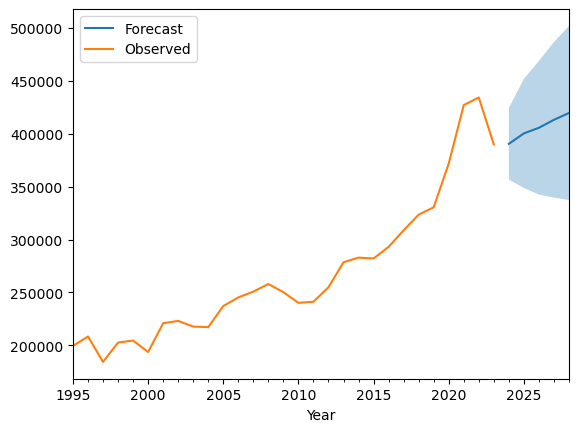

In [36]:
forecast = result.get_forecast(steps=5)
ci = forecast.conf_int()

forecast.predicted_mean.plot(label='Forecast')
data['Undertrials'].plot(label='Observed')
plt.fill_between(ci.index, ci.iloc[:,0], ci.iloc[:,1], alpha=0.3)
plt.legend()

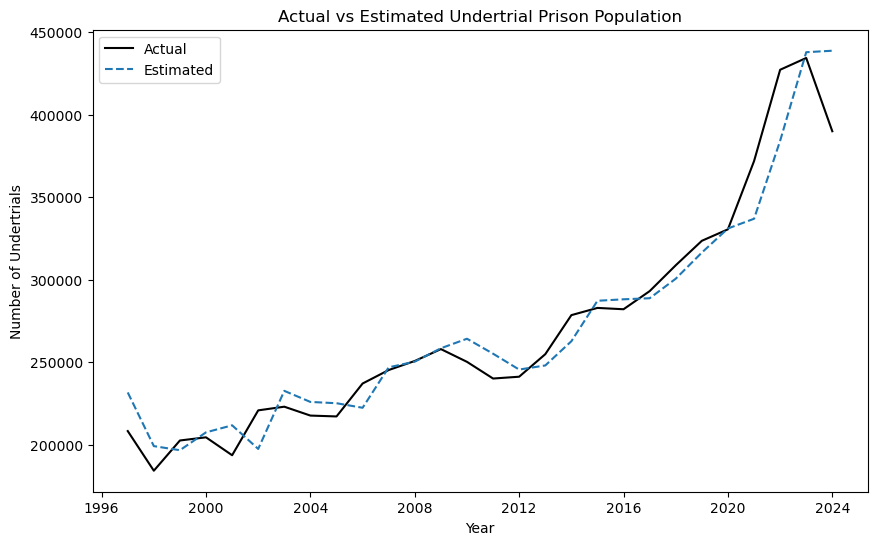

In [37]:
fitted_levels = result.predict(start=data.index[1], end=data.index[-1], typ='levels')
comparison = pd.DataFrame({
    'Actual': data['Undertrials'],
    'Estimated': fitted_levels
})

comparison = comparison.dropna()
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.plot(comparison.index, comparison['Actual'], label='Actual', color='black')
plt.plot(comparison.index, comparison['Estimated'], label='Estimated', linestyle='--')

plt.title('Actual vs Estimated Undertrial Prison Population')
plt.xlabel('Year')
plt.ylabel('Number of Undertrials')
plt.legend()
plt.show()
